# Predicting House Prices in Ames, Iowa

**Project 2 — Kaggle regression challenge**

**Goal.** Predict `SalePrice` for every house in `test.csv`. Submissions are scored by **root mean squared error (RMSE)** in dollars: the public leaderboard uses 60% of the test set and the final private leaderboard uses the other 40%.

**Approach in one line.** Clean the data according to what each missing value actually means, encode the quality ratings as numbers, add a handful of summary features, then compare several scikit-learn models with 5-fold cross-validation and submit a blend of the two strongest.

| Section | What happens |
|---|---|
| 1. Setup | Imports, load data |
| 2. Exploring the target | Why we model `log(SalePrice)` |
| 3. Missing values | Most "missing" values mean "the house doesn't have one" |
| 4. Key relationships and outliers | Which features matter; two training rows we drop |
| 5. Feature engineering | Ordinal encoding and new features |
| 6. Preprocessing pipeline | Imputation, scaling, one-hot encoding |
| 7. Model comparison | Six models under the same cross-validation |
| 8. Final model | Lasso + Gradient Boosting blend |
| 9. Submission | Fit on all training data, predict, sanity-check, save |
| 10. Takeaways | What worked, what didn't, what we'd try next |

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.compose import make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              GradientBoostingRegressor, VotingRegressor)
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train:", train.shape, " test:", test.shape)
train.head()

train: (1095, 81)  test: (365, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1024,120,RL,43.0,3182,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Blmngtn,Norm,Norm,TwnhsE,1Story,7,5,2005,2006,Gable,CompShg,VinylSd,VinylSd,BrkFace,14.0,Gd,TA,PConc,Gd,Gd,No,GLQ,16,Unf,0,1330,1346,GasA,Ex,Y,SBrkr,1504,0,0,1504,0,0,2,0,2,1,Gd,7,Typ,1,Gd,Attchd,2005.0,Fin,2,437,TA,TA,Y,156,20,0,0,0,0,NaN,NaN,NaN,0,5,2008,WD,Normal,191000
1,811,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1974,1999,Hip,CompShg,HdBoard,HdBoard,BrkFace,99.0,TA,TA,CBlock,TA,TA,No,ALQ,663,LwQ,377,0,1040,GasA,Fa,Y,SBrkr,1309,0,0,1309,1,0,1,1,3,1,Gd,5,Typ,1,Fa,Attchd,1974.0,RFn,2,484,TA,TA,Y,265,0,0,0,0,648,Fa,GdPrv,NaN,0,1,2006,WD,Normal,181000
2,1385,50,RL,60.0,9060,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1.5Fin,6,5,1939,1950,Gable,CompShg,WdShing,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,TA,Mn,Rec,204,Unf,0,356,560,GasA,TA,Y,SBrkr,698,560,0,1258,0,0,1,0,2,1,TA,6,Typ,0,NaN,Detchd,1939.0,Unf,1,280,TA,TA,P,0,0,0,0,0,0,NaN,MnPrv,NaN,0,10,2009,WD,Normal,105000
3,627,20,RL,NaN,12342,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,5,1960,1978,Hip,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,CBlock,TA,TA,No,Unf,0,Unf,0,978,978,GasA,TA,Y,SBrkr,1422,0,0,1422,0,0,1,0,3,1,TA,6,Min1,1,TA,Attchd,1960.0,RFn,1,286,TA,TA,Y,0,0,36,0,0,0,NaN,GdWo,Shed,600,8,2007,WD,Normal,139900
4,814,20,RL,75.0,9750,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Gable,CompShg,MetalSd,MetalSd,BrkFace,243.0,TA,TA,CBlock,TA,TA,No,Rec,608,Unf,0,834,1442,GasA,Gd,Y,SBrkr,1442,0,0,1442,0,0,1,1,4,1,TA,7,Typ,0,NaN,Attchd,1958.0,RFn,1,301,TA,TA,Y,0,0,275,0,0,0,NaN,NaN,Shed,500,4,2007,COD,Normal,157900


The training set has 1,095 houses and 81 columns (an `Id`, 79 features and the target `SalePrice`). The test set has 365 houses with the same columns minus `SalePrice`. About half of the features are categorical (text), the rest numeric.

## 2. Exploring the target

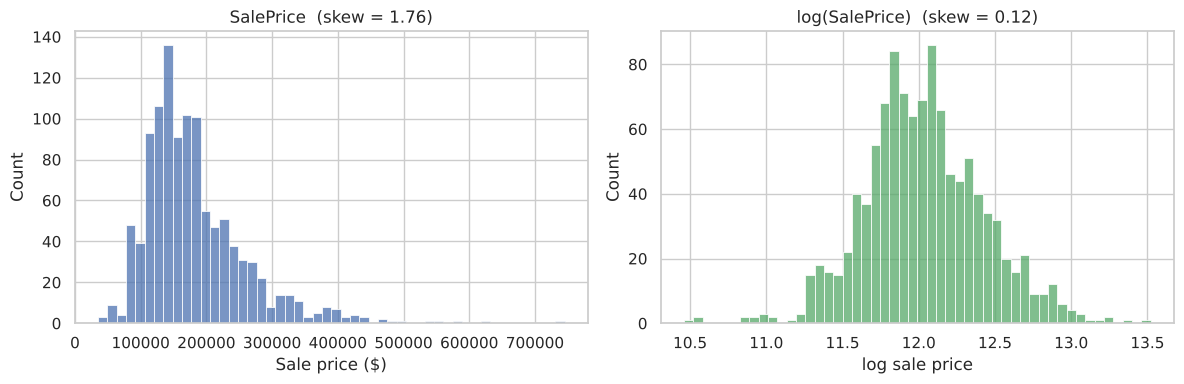

count      1,095
mean     181,712
std       77,955
min       34,900
25%      130,000
50%      165,000
75%      215,000
max      745,000
Name: SalePrice, dtype: str

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["SalePrice"], bins=50, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"SalePrice  (skew = {train['SalePrice'].skew():.2f})")
axes[0].set_xlabel("Sale price ($)")
sns.histplot(np.log(train["SalePrice"]), bins=50, ax=axes[1], color="#55A868")
axes[1].set_title(f"log(SalePrice)  (skew = {np.log(train['SalePrice']).skew():.2f})")
axes[1].set_xlabel("log sale price")
plt.tight_layout()
plt.show()

train["SalePrice"].describe().apply(lambda v: f"{v:,.0f}")

**Observation.** Prices are strongly right-skewed (skew ≈ 1.76): most houses sell between \$130k and \$215k, but a long tail runs past \$700k. After a log transform the distribution is close to symmetric (skew ≈ 0.12).

**Decision.** For the linear models we fit on `log(SalePrice)` and convert predictions back with `exp()`. This matters for two reasons:

1. Price effects are roughly *multiplicative*: an extra bathroom adds a percentage to the price, not a fixed dollar amount. A log target lets a linear model capture that.
2. On the raw scale, a few expensive houses dominate the squared-error loss.

We wrap this in scikit-learn's `TransformedTargetRegressor`, so every model is still **evaluated on RMSE in dollars**, the same metric Kaggle uses.

## 3. Missing values

In [4]:
missing = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "test_missing": test.isna().sum(),
})
missing["train_pct"] = (missing["train_missing"] / len(train) * 100).round(1)
missing = missing[(missing.train_missing > 0) | (missing.test_missing > 0)]
missing.sort_values("train_missing", ascending=False)

,train_missing,test_missing,train_pct
PoolQC,1089,364.0,99.5
MiscFeature,1052,354.0,96.1
Alley,1025,344.0,93.6
Fence,877,302.0,80.1
MasVnrType,639,233.0,58.4
FireplaceQu,512,178.0,46.8
LotFrontage,200,59.0,18.3
GarageYrBlt,58,23.0,5.3
GarageType,58,23.0,5.3
GarageFinish,58,23.0,5.3


**Most of these are not really missing.** The data dictionary says that `NA` in columns like `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, the `Garage*` columns and the `Bsmt*` columns means *"no pool"*, *"no alley access"*, *"no garage"*, and so on. For example, all garage columns are missing for exactly the same 58 houses — the houses without a garage.

So rather than filling these with the most common value (which would invent a garage for a house that has none), we treat them as their own category:

| Column(s) | `NA` means | How we fill it |
|---|---|---|
| Quality / condition ratings (`PoolQC`, `FireplaceQu`, `GarageQual`, `BsmtQual`, …) | Feature absent | `0` on the ordinal scale (below "Poor") |
| `Alley`, `Fence`, `MiscFeature`, `GarageType`, `MasVnrType` | Feature absent | the string `"None"` |
| `MasVnrArea` | No masonry veneer | `0` |
| `GarageYrBlt` | No garage | the house's `YearBuilt` (keeps the column numeric without an extreme placeholder) |
| `LotFrontage` (18% missing) | Genuinely unrecorded | median lot frontage **of the same neighborhood** — lots on the same streets tend to be similar |
| `Electrical` (1 row) | Genuinely unrecorded | most frequent value (handled by the pipeline) |

## 4. Key relationships and outliers

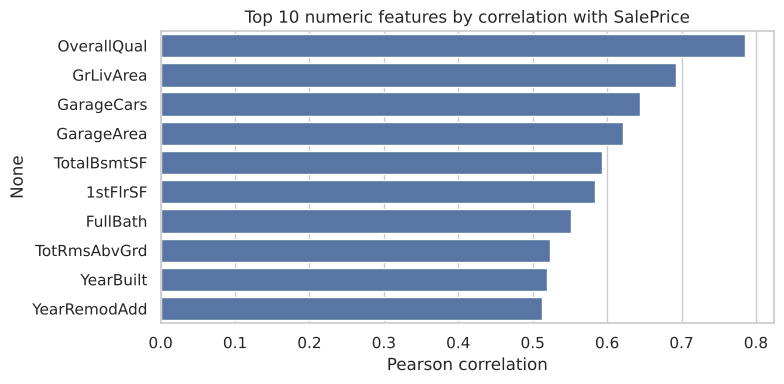

In [5]:
corr = (train.select_dtypes("number").drop(columns="Id")
        .corr()["SalePrice"].drop("SalePrice")
        .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=corr.values, y=corr.index, color="#4C72B0", ax=ax)
ax.set_title("Top 10 numeric features by correlation with SalePrice")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

**Overall quality** (`OverallQual`, r ≈ 0.79) and **above-ground living area** (`GrLivArea`, r ≈ 0.69) are the two strongest single predictors, followed by garage size and basement area. Several of these overlap (`GarageCars` vs. `GarageArea`, `TotalBsmtSF` vs. `1stFlrSF`), which is one reason regularized models (Ridge / Lasso) should beat plain linear regression here.

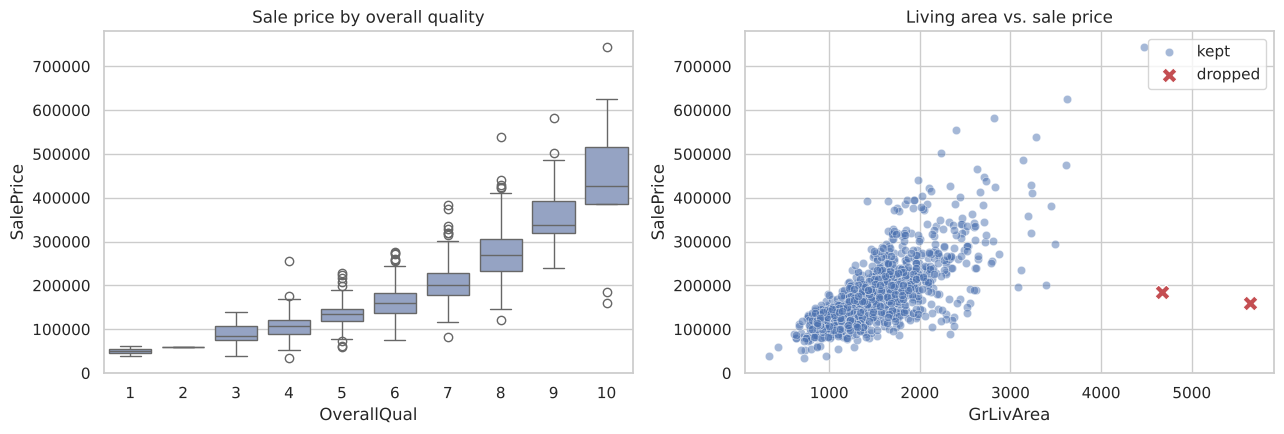

,Id,GrLivArea,OverallQual,SalePrice,SaleCondition
292,524,4676,10,184750,Partial
422,1299,5642,10,160000,Partial


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=train, x="OverallQual", y="SalePrice", color="#8DA0CB", ax=axes[0])
axes[0].set_title("Sale price by overall quality")

outlier_mask = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)
sns.scatterplot(data=train[~outlier_mask], x="GrLivArea", y="SalePrice",
                alpha=0.5, ax=axes[1], color="#4C72B0", label="kept")
sns.scatterplot(data=train[outlier_mask], x="GrLivArea", y="SalePrice",
                s=120, color="#C44E52", marker="X", ax=axes[1], label="dropped")
axes[1].set_title("Living area vs. sale price")
plt.tight_layout()
plt.show()

train.loc[outlier_mask, ["Id", "GrLivArea", "OverallQual", "SalePrice", "SaleCondition"]]

**Outliers.** Two houses are enormous (4,600+ sq ft, top quality rating) but sold for \$160k–\$185k, far below the trend. Both have `SaleCondition = "Partial"`, meaning the house was not finished when assessed, so the recorded price doesn't reflect a normal sale of the finished home. The dataset's author also recommends removing houses over 4,000 sq ft for exactly this reason.

**Decision.** We drop these two rows from training. We keep the other large house (\$745k), because its price *is* consistent with its size. In testing, keeping the two outliers made the linear models dramatically worse: one bad lever point pulls the whole regression line.

Note: the test set contains one house over 4,000 sq ft (a normal sale, quality 10). Because we keep the large, correctly priced training house, the model still has a reasonable reference for it.

In [7]:
train = train[~outlier_mask].reset_index(drop=True)
print("training rows after removing outliers:", len(train))

training rows after removing outliers: 1093


## 5. Feature engineering

Two kinds of changes:

**(a) Encode ordinal ratings as numbers.** Columns such as `KitchenQual` use the scale Ex > Gd > TA > Fa > Po. One-hot encoding would throw away that ordering, so we map them to 5 → 1 (and 0 for "doesn't exist"). The same applies to basement exposure and finish type, garage finish, functionality, lot shape, land slope, and paved driveway.

**(b) Add summary features** that capture what buyers actually think about:

| New feature | Definition | Why |
|---|---|---|
| `TotalSF` | basement + 1st floor + 2nd floor area | total usable space in one number |
| `TotalBath` | full baths + ½ × half baths, above ground and basement | bathrooms are split across four columns |
| `HouseAge` | `YrSold − YearBuilt` | age at time of sale, not calendar year |
| `RemodAge` | `YrSold − YearRemodAdd` | how recently it was updated |
| `TotalPorchSF` | sum of all porch and deck areas | five sparse columns → one |
| `QualxSF` | `OverallQual × GrLivArea` | a large house is worth more when it is also well built |

We also convert `MSSubClass` (dwelling type code, e.g. `20`, `60`) to text: the numbers are labels, not quantities.

In [8]:
QUAL = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1}
ORDINAL_MAPS = {
    "ExterQual": QUAL, "ExterCond": QUAL, "BsmtQual": QUAL, "BsmtCond": QUAL,
    "HeatingQC": QUAL, "KitchenQual": QUAL, "FireplaceQu": QUAL,
    "GarageQual": QUAL, "GarageCond": QUAL, "PoolQC": QUAL,
    "BsmtExposure": {"Gd": 4, "Av": 3, "Mn": 2, "No": 1},
    "BsmtFinType1": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1},
    "BsmtFinType2": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1},
    "GarageFinish": {"Fin": 3, "RFn": 2, "Unf": 1},
    "Functional": {"Typ": 7, "Min1": 6, "Min2": 5, "Mod": 4, "Maj1": 3,
                   "Maj2": 2, "Sev": 1, "Sal": 0},
    "LotShape": {"Reg": 3, "IR1": 2, "IR2": 1, "IR3": 0},
    "LandSlope": {"Gtl": 2, "Mod": 1, "Sev": 0},
    "PavedDrive": {"Y": 2, "P": 1, "N": 0},
    "CentralAir": {"Y": 1, "N": 0},
}
NONE_MEANS_ABSENT = ["Alley", "Fence", "MiscFeature", "MasVnrType", "GarageType"]

# Neighborhood medians are computed from TRAINING data only, then reused for test.
lot_frontage_by_nbhd = train.groupby("Neighborhood")["LotFrontage"].median()


def engineer(df):
    d = df.copy()

    # (a) ordinal ratings -> numbers; NA ("feature absent") -> 0
    for col, mapping in ORDINAL_MAPS.items():
        d[col] = d[col].map(mapping).fillna(0)

    # NA that means "none" -> explicit category
    for col in NONE_MEANS_ABSENT:
        d[col] = d[col].fillna("None")

    d["MSSubClass"] = d["MSSubClass"].astype(str)
    d["MasVnrArea"] = d["MasVnrArea"].fillna(0)
    d["GarageYrBlt"] = d["GarageYrBlt"].fillna(d["YearBuilt"])
    d["LotFrontage"] = d["LotFrontage"].fillna(d["Neighborhood"].map(lot_frontage_by_nbhd))

    # (b) new features
    d["TotalSF"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
    d["TotalBath"] = (d["FullBath"] + 0.5 * d["HalfBath"]
                      + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"])
    d["HouseAge"] = d["YrSold"] - d["YearBuilt"]
    d["RemodAge"] = d["YrSold"] - d["YearRemodAdd"]
    d["TotalPorchSF"] = d[["OpenPorchSF", "EnclosedPorch", "3SsnPorch",
                           "ScreenPorch", "WoodDeckSF"]].sum(axis=1)
    d["QualxSF"] = d["OverallQual"] * d["GrLivArea"]

    return d.drop(columns=["Id"])


X = engineer(train.drop(columns="SalePrice"))
y = train["SalePrice"]
X_test = engineer(test)

print("features:", X.shape[1])
print("remaining missing values in X:", int(X.isna().sum().sum()))
print("remaining missing values in X_test:", int(X_test.isna().sum().sum()))

features: 85
remaining missing values in X: 1
remaining missing values in X_test: 0


In [9]:
new_feats = ["TotalSF", "QualxSF", "TotalBath", "HouseAge", "RemodAge", "TotalPorchSF"]
X[new_feats].assign(SalePrice=y).corr()["SalePrice"].drop("SalePrice").round(3).sort_values(ascending=False)

QualxSF         0.870
TotalSF         0.829
TotalBath       0.627
TotalPorchSF    0.388
RemodAge       -0.515
HouseAge       -0.520
Name: SalePrice, dtype: float64

`QualxSF` and `TotalSF` (r ≈ 0.87 and 0.83) are now **stronger than any original feature** — better than `OverallQual` alone (0.79). `HouseAge` is negatively correlated as expected: older houses sell for less.

## 6. Preprocessing pipeline

The remaining steps go inside a scikit-learn `Pipeline`, so that during cross-validation they are **fit only on the training folds** (no information leaks from the validation fold):

- **Numeric columns:** fill any remaining gaps with the median, then standardize (mean 0, sd 1). Standardizing matters for Ridge and Lasso, whose penalty treats all coefficients equally. Tree models don't need it, so we skip it for them.
- **Categorical columns:** fill gaps with the most frequent value, then one-hot encode.
  - `handle_unknown="ignore"`: the test set contains a few categories never seen in training (e.g. `RoofMatl = "Membran"`, `Electrical = "Mix"`). These become all-zero rows instead of crashing.
  - `min_frequency=5`: categories with fewer than 5 houses are grouped together, to avoid fitting noise from one or two sales.

In [10]:
numeric_cols = make_column_selector(dtype_include="number")
categorical_cols = make_column_selector(dtype_exclude="number")


def preprocessor(scale=True):
    numeric_steps = [SimpleImputer(strategy="median")]
    if scale:
        numeric_steps.append(StandardScaler())
    return ColumnTransformer([
        ("num", make_pipeline(*numeric_steps), numeric_cols),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", min_frequency=5)),
         categorical_cols),
    ])


def log_target(model):
    # Fit on log(SalePrice), predict back in dollars.
    return TransformedTargetRegressor(regressor=model, func=np.log, inverse_func=np.exp)

## 7. Model comparison

We compare six models under the **same** 5-fold cross-validation split, scored by RMSE in dollars:

| Model | Why it's in the comparison |
|---|---|
| Linear regression (raw price) | baseline: no regularization, no log target |
| Ridge (log price) | L2 penalty shrinks correlated coefficients |
| Lasso (log price) | L1 penalty can set unhelpful coefficients to exactly 0 (built-in feature selection) |
| Random forest | non-linear, captures interactions automatically |
| Histogram gradient boosting (log price) | fast boosted trees |
| Gradient boosting (log price) | slower boosted trees with row/column subsampling |

`RidgeCV` and `LassoCV` choose their penalty strength by internal cross-validation on each training fold.

In [11]:
models = {
    "Linear regression (raw y)": make_pipeline(preprocessor(), LinearRegression()),
    "Ridge (log y)": log_target(make_pipeline(
        preprocessor(), RidgeCV(alphas=np.logspace(-1, 3, 30)))),
    "Lasso (log y)": log_target(make_pipeline(
        preprocessor(), LassoCV(alphas=np.logspace(-4.5, -1.5, 30), max_iter=50_000))),
    "Random forest": make_pipeline(
        preprocessor(scale=False),
        RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)),
    "Hist. gradient boosting (log y)": log_target(make_pipeline(
        preprocessor(scale=False),
        HistGradientBoostingRegressor(learning_rate=0.05, max_iter=600, max_leaf_nodes=15,
                                      l2_regularization=1.0, random_state=RANDOM_STATE))),
    "Gradient boosting (log y)": log_target(make_pipeline(
        preprocessor(scale=False),
        GradientBoostingRegressor(n_estimators=1500, learning_rate=0.02, max_depth=3,
                                  subsample=0.8, max_features="sqrt",
                                  random_state=RANDOM_STATE))),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []
for name, model in models.items():
    rmse = -cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error")
    results.append({"model": name, "cv_rmse": rmse.mean(), "std": rmse.std()})

results = pd.DataFrame(results).sort_values("cv_rmse").reset_index(drop=True)
results.style.format({"cv_rmse": "${:,.0f}", "std": "±${:,.0f}"})

,model,cv_rmse,std
0,Lasso (log y),"$20,385","±$2,123"
1,Ridge (log y),"$20,718","±$2,005"
2,Gradient boosting (log y),"$21,550","±$3,466"
3,Hist. gradient boosting (log y),"$25,183","±$3,365"
4,Linear regression (raw y),"$25,594","±$1,972"
5,Random forest,"$26,128","±$3,452"


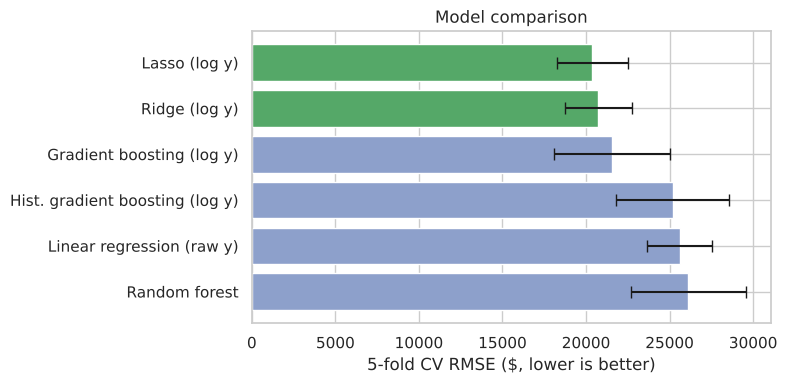

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#55A868" if i < 2 else "#8DA0CB" for i in range(len(results))]
ax.barh(results["model"], results["cv_rmse"], xerr=results["std"], color=colors, capsize=4)
ax.invert_yaxis()
ax.set_xlabel("5-fold CV RMSE ($, lower is better)")
ax.set_title("Model comparison")
plt.tight_layout()
plt.show()

**What the comparison shows:**

- **The log target plus regularization is the biggest win.** Plain linear regression on raw prices lands around \$25.6k RMSE; Ridge and Lasso on log prices cut that to roughly \$20.5k — about 20% lower error from the same features.
- **Lasso slightly beats Ridge**, consistent with many of the ~200 one-hot columns carrying little signal; Lasso zeros them out.
- **Gradient boosting is the best tree model** (≈ \$21.6k), but it doesn't beat Lasso. With only ~1,100 houses, and engineered features that already capture the main interaction (`QualxSF`), a well-regularized linear model is hard to beat.
- **Random forest and histogram gradient boosting trail far behind** (≈ \$25–26k), no better than the plain linear baseline. Random forest in particular can't predict beyond the range of prices it has seen, which hurts on the expensive tail.

## 8. Final model: blending Lasso and Gradient Boosting

Lasso and gradient boosting make *different kinds of mistakes*: Lasso assumes effects are additive on the log scale; boosted trees find thresholds and interactions but extrapolate poorly. Averaging their predictions should cancel some of each model's errors.

We test a few weights using out-of-fold predictions (each house is predicted by a model that never saw it).

In [13]:
oof = {name: cross_val_predict(models[name], X, y, cv=cv)
       for name in ["Lasso (log y)", "Gradient boosting (log y)"]}

def rmse(pred):
    return np.sqrt(np.mean((y - pred) ** 2))

blend_scores = pd.DataFrame({
    "lasso_weight": w,
    "gbr_weight": 1 - w,
    "oof_rmse": rmse(w * oof["Lasso (log y)"] + (1 - w) * oof["Gradient boosting (log y)"]),
} for w in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0])
blend_scores.style.format({"oof_rmse": "${:,.0f}", "lasso_weight": "{:.1f}", "gbr_weight": "{:.1f}"})

,lasso_weight,gbr_weight,oof_rmse
0,0.0,1.0,"$21,831"
1,0.3,0.7,"$20,525"
2,0.4,0.6,"$20,253"
3,0.5,0.5,"$20,067"
4,0.6,0.4,"$19,972"
5,0.7,0.3,"$19,968"
6,1.0,0.0,"$20,498"


Every blend between 0.3 and 0.7 beats both models on their own. Weights of 0.6 and 0.7 are essentially tied for the lowest error (≈ \$19,970, a difference of a few dollars), and the curve is flat across that range, so the result doesn't hinge on picking the weight precisely. We use **60% Lasso / 40% gradient boosting**, keeping a meaningful share for the tree model so the blend gets the benefit of both.

We implement the blend with scikit-learn's `VotingRegressor`, which averages its members' predictions with the given weights. Because each member is a `TransformedTargetRegressor`, the averaging happens in **dollars**.

In [14]:
final_model = VotingRegressor(
    estimators=[
        ("lasso", models["Lasso (log y)"]),
        ("gbr", models["Gradient boosting (log y)"]),
    ],
    weights=[0.6, 0.4],
)

final_cv = -cross_val_score(final_model, X, y, cv=cv, scoring="neg_root_mean_squared_error")
print(f"Final blend, 5-fold CV RMSE: ${final_cv.mean():,.0f} ± ${final_cv.std():,.0f}")

Final blend, 5-fold CV RMSE: $19,802 ± $2,573


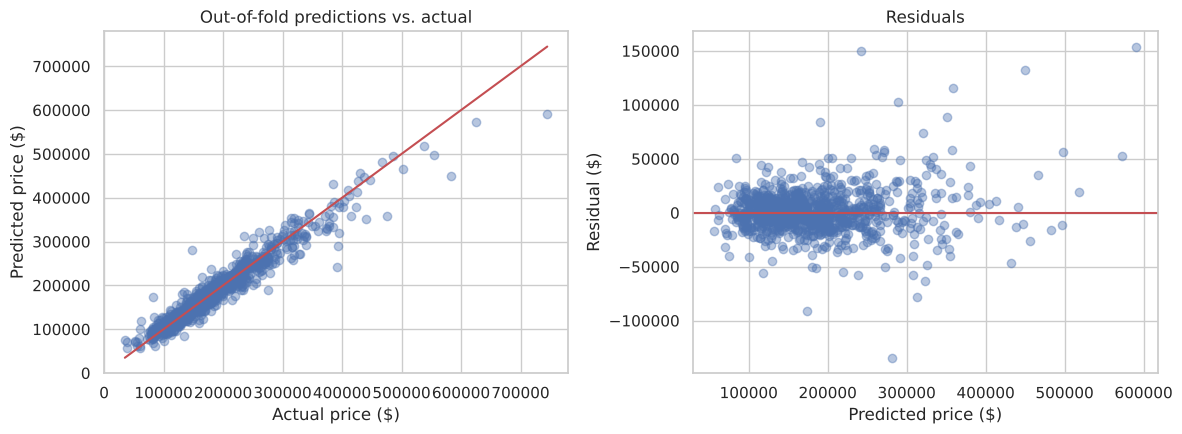

In [15]:
pred_oof = 0.6 * oof["Lasso (log y)"] + 0.4 * oof["Gradient boosting (log y)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y, pred_oof, alpha=0.4, color="#4C72B0")
lims = [y.min(), y.max()]
axes[0].plot(lims, lims, color="#C44E52", lw=1.5)
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Out-of-fold predictions vs. actual")

axes[1].scatter(pred_oof, y - pred_oof, alpha=0.4, color="#4C72B0")
axes[1].axhline(0, color="#C44E52", lw=1.5)
axes[1].set_xlabel("Predicted price ($)")
axes[1].set_ylabel("Residual ($)")
axes[1].set_title("Residuals")
plt.tight_layout()
plt.show()

Predictions track actual prices closely for the bulk of houses. Residuals fan out somewhat at higher prices: in dollar terms, expensive houses carry larger errors, which is expected when the model works on a percentage (log) scale. There's no strong curved pattern in the residuals, so the model isn't systematically missing a non-linear trend.

Lasso alpha chosen: 0.00055
Non-zero coefficients: 96 of 221


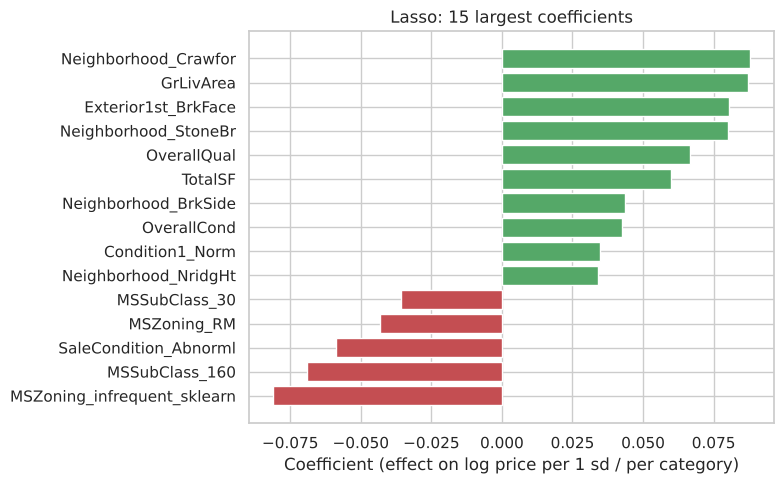

In [16]:
final_model.fit(X, y)

lasso = final_model.named_estimators_["lasso"].regressor_[-1]
feature_names = final_model.named_estimators_["lasso"].regressor_[0].get_feature_names_out()
coefs = pd.Series(lasso.coef_, index=feature_names)

print(f"Lasso alpha chosen: {lasso.alpha_:.5f}")
print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}")

top = coefs[coefs != 0].sort_values(key=np.abs, ascending=False).head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([n.split("__", 1)[1] for n in top.index], top.values,
        color=["#C44E52" if v < 0 else "#55A868" for v in top.values])
ax.set_xlabel("Coefficient (effect on log price per 1 sd / per category)")
ax.set_title("Lasso: 15 largest coefficients")
plt.tight_layout()
plt.show()

**Reading the coefficients.** Because the target is `log(SalePrice)` and numeric features are standardized, a coefficient of 0.05 means *one standard deviation more of this feature → roughly 5% higher price*, holding everything else fixed. Categorical coefficients are relative to houses not in that category.

Lasso set more than half of the 221 encoded columns to exactly 0. The largest surviving effects line up with intuition:

- **Size and quality push prices up:** `GrLivArea`, `OverallQual`, `TotalSF`, `OverallCond`.
- **Location matters:** Crawford, Stone Brook, Brookside and Northridge Heights carry a premium over otherwise similar houses.
- **Some dwelling and sale types sell for less:** 2-story PUD townhouses (`MSSubClass` 160), medium-density and rare zoning classes, and abnormal sales (foreclosures, short sales).

`QualxSF` doesn't appear in the top 15 even though it has the highest correlation: it overlaps heavily with `GrLivArea` and `OverallQual`, so Lasso spreads the credit across them. Coefficients of correlated features should be read as a group, not one at a time.

## 9. Submission

In [17]:
test_pred = final_model.predict(X_test)

submission = pd.DataFrame({"Id": test["Id"], "SalePrice": test_pred})

# Sanity checks before uploading
assert len(submission) == len(test) == 365
assert submission["Id"].is_unique
assert submission["SalePrice"].notna().all() and (submission["SalePrice"] > 0).all()

print(submission["SalePrice"].describe().apply(lambda v: f"{v:,.0f}"))
print("\nTraining prices for comparison:")
print(y.describe().apply(lambda v: f"{v:,.0f}"))

submission.to_csv("submission.csv", index=False)
submission.head()

count        365
mean     177,047
std       78,940
min       50,901
25%      125,401
50%      153,926
75%      208,918
max      703,483
Name: SalePrice, dtype: str

Training prices for comparison:
count      1,093
mean     181,729
std       78,024
min       34,900
25%      130,000
50%      165,000
75%      215,000
max      745,000
Name: SalePrice, dtype: str


,Id,SalePrice
0,893,145694.071717
1,1106,329283.130807
2,414,101876.221666
3,523,155343.649023
4,1037,315591.819559


The predicted prices have a similar center and spread to the training prices, with no missing, negative or duplicate values. `submission.csv` has the required `Id,SalePrice` header and one row per test house.

## 10. Takeaways

**What made the biggest difference**

1. **Modeling log price.** Matches how prices actually behave (percentage effects) and stops a few expensive houses from dominating the fit.
2. **Removing two non-representative sales.** Two unfinished mega-houses sold at a fraction of their value; keeping them badly distorted the linear models.
3. **Treating `NA` correctly.** Most missing values mean "this house has no garage / pool / fence", not "unknown". Encoding them as absent preserves real information.
4. **Ordinal encoding and a few domain features.** `TotalSF` and `QualxSF` end up more predictive than any single original column.

**What didn't help as much as expected:** random forest and histogram gradient boosting both trailed the regularized linear models on this small dataset.

**Limitations**

- Cross-validation RMSE (≈ \$20k) is our best estimate of leaderboard performance, but the private leaderboard uses a different 40% of test houses, so the score can move.
- Blend weights were chosen on the same CV folds used to evaluate them. The flat weight curve suggests little overfitting, but it isn't a fully independent check.

**Next steps we'd try**

- Log-transform heavily skewed numeric features (e.g. `LotArea`) before Lasso.
- Tune gradient boosting more systematically (`GridSearchCV` over depth, learning rate, number of trees).
- Add more learners to the blend (e.g. `ElasticNetCV`, `SVR`) or use `StackingRegressor` to learn the weights.